# Integration · detector → classifier → segmentation, one call per image

## 0. Settings, packages, mount Drive

In [1]:
!pip -q install ultralytics onnxruntime-gpu

In [2]:
DRIVE_PROJECT = '/content/drive/MyDrive/AI251P_Capstone_CrossDomainAerial'   # the only Drive path
# paths are relative to DRIVE_PROJECT (or absolute)
CLS_DIR     = '02_Classification/Export/2026-10-31_ClsResNet18_s43_v1'   # model.onnx + classify.py (T1)
DET_WEIGHTS = '03_Detection/2026-11-04_P08_Baseline/YOLO11n_Joint_StrongerAug/weights/best.pt'   # YOLO11n detector (T2)
DET_CONF, DET_IOU, DET_IMGSZ = 0.25, 0.7, 640                            # imgsz and NMS IoU as in its args.yaml
SEG_WEIGHTS = '04_Segmentation/seg/yolo11n_seg_1280/weights/last.pt'     # YOLO11n-seg (T3), 1280 px; last.pt = the checkpoint approved in section 3
SEG_BACKEND = 'yolo-seg'
SEG = dict(conf=0.25, imgsz=1280, match_iou=0.3)

FRAMES_DIR = '04_Segmentation/seg/yolo_dataset/images/val'               # val frames of the segmentation dataset
N_FRAMES, FRAME_SEED, WARMUP = 100, 42, 10
ALTITUDE_M, HFOV_DEG = None, None   # size in metres only when both are set (nadir view)
BUDGET_P95_MS = 200           # whole system, per frame (P17)
N_FIGURES = 6

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Imports and paths

In [3]:
import os, re, sys, json, time, math, datetime
from pathlib import Path
import numpy as np, pandas as pd, torch, cv2
import ultralytics, onnxruntime as ort

ROOT = Path(DRIVE_PROJECT)
def P(x): return None if x is None else (Path(x) if str(x).startswith('/') else ROOT / x)
def rel(p):
    try: return Path(p).relative_to(ROOT).as_posix()
    except ValueError: return str(p)
CLS, DET_W, SEG_W = P(CLS_DIR), P(DET_WEIGHTS), P(SEG_WEIGHTS)
for name, p in (('classifier model.onnx', CLS / 'model.onnx'), ('detector', DET_W)) + ((('segmentation', SEG_W),) if SEG_W else ()):
    if not p.is_file(): raise FileNotFoundError(f'{name} not found: {p} (set the path in section 0)')

REPORT = []
def check(name, expected, actual, ok=None):
    ok = (expected == actual) if ok is None else bool(ok)
    REPORT.append({'check': name, 'expected': str(expected), 'actual': str(actual), 'pass': ok})
    print(f"{'PASS' if ok else 'FAIL'}  {name}: expected {expected}, actual {actual}")
    assert ok, f'check failed: {name}'
def verdict(name, target, actual, ok):
    REPORT.append({'check': name, 'expected': str(target), 'actual': str(actual), 'pass': True, 'status': 'MET' if ok else 'NOT MET'})
    print(f"{'MET' if ok else 'NOT MET'}  {name}: target {target}, actual {actual}")

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
GPU = torch.cuda.get_device_name(0) if DEVICE == 'cuda' else None
VERSIONS = {'python': sys.version.split()[0], 'torch': torch.__version__, 'ultralytics': ultralytics.__version__,
            'onnxruntime': ort.__version__, 'opencv': cv2.__version__, 'gpu': GPU}
print(json.dumps(VERSIONS, indent=1))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
{
 "python": "3.13.16",
 "torch": "2.14.1+cu130",
 "ultralytics": "8.4.215",
 "onnxruntime": "1.32.0",
 "opencv": "4.14.0",
 "gpu": "Tesla T4"
}


## 2. Output folder

In [4]:
TODAY = time.strftime('%Y-%m-%d')
INT_DIR = ROOT / '04_Integration'; INT_DIR.mkdir(parents=True, exist_ok=True)
VERSION = max([int(m.group(1)) for f in os.listdir(INT_DIR) if (m := re.fullmatch(rf'{TODAY}_Pipeline_v(\d+)', f))], default=0) + 1
OUT = INT_DIR / f'{TODAY}_Pipeline_v{VERSION}'
OUT.mkdir(); (OUT / 'figures').mkdir()
print('output folder:', rel(OUT))

output folder: 04_Integration/2026-11-16_Pipeline_v1


## 3. `pipeline.py`: one call per image

In [5]:
PIPELINE_SRC = r"""# AI251P integration pipeline: detector -> classifier -> segmentation, one call per image.
#
#     pipe = Pipeline(det_weights, cls_onnx, det_conf, det_iou, det_imgsz, seg_weights=None, seg_backend=None)
#     result = pipe.analyze(frame_rgb, altitude_m=None, hfov_deg=None)
#
# frame_rgb: numpy uint8 H x W x 3, RGB (OpenCV frames: frame[..., ::-1]).
# result['objects']: one dict per detected object
#     class, confidence           classifier (T1) output, raw logits -> max softmax
#     det_class, det_confidence   detector (T2) output
#     box_xywh                    x, y (top-left), w, h in frame pixels (detector box, clipped to the frame)
#     mask                        None, or {'origin_xy': (x0, y0), 'bitmap': uint8 h x w (1 = object)} inside the box
#     seg_iou                     box IoU of the matched segmentation instance (None if no mask)
#     size                        area_px, length_px, width_px, source ('mask' | 'box'), gsd_m_per_px, length_m, width_m, area_m2
#                                 metres are None unless altitude_m and hfov_deg are given (nadir view assumed)
# result['timing_ms']: detect, classify, segment, size, total
import time, math, numpy as np, cv2
import classify as clf

def _iou(a, b):
    x1, y1, x2, y2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    i = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    u = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - i
    return i / u if u > 0 else 0.0

def _match(det_xyxy, seg_xyxy, thr):
    # greedy one-to-one match by box IoU, highest first; returns {det index: (seg index, iou)}
    pairs = sorted(((_iou(d, s), i, j) for i, d in enumerate(det_xyxy) for j, s in enumerate(seg_xyxy)), reverse=True)
    out, used = {}, set()
    for v, i, j in pairs:
        if v < thr: break
        if i in out or j in used: continue
        out[i] = (j, v); used.add(j)
    return out

class Pipeline:
    def __init__(self, det_weights, cls_onnx, det_conf, det_iou, det_imgsz=640, seg_weights=None, seg_backend=None,
                 seg_conf=0.25, seg_imgsz=640, seg_match_iou=0.3, device=None, max_det=300):
        import torch
        from ultralytics import YOLO
        self.device = device or ('cuda' if torch.cuda.is_available() else 'cpu')
        self.det = YOLO(str(det_weights))
        self.det_names = self.det.names
        self.det_kw = dict(conf=det_conf, iou=det_iou, imgsz=det_imgsz, max_det=max_det, verbose=False, device=self.device)
        self.cls = clf.load(cls_onnx)
        self.seg_backend, self.seg = seg_backend, None
        self.seg_conf, self.seg_imgsz, self.seg_match_iou = seg_conf, seg_imgsz, seg_match_iou
        if seg_weights and seg_backend == 'yolo-seg':
            self.seg = YOLO(str(seg_weights))
        elif seg_weights and seg_backend == 'maskrcnn-torchvision':
            import torchvision
            ck = torch.load(str(seg_weights), map_location='cpu', weights_only=True)
            if not (isinstance(ck, dict) and 'model' in ck and 'num_classes' in ck):
                raise ValueError("Mask R-CNN checkpoint must be a dict with 'model' (state_dict) and 'num_classes'")
            m = torchvision.models.detection.maskrcnn_resnet50_fpn_v2(weights=None, weights_backbone=None, num_classes=int(ck['num_classes']))
            m.load_state_dict(ck['model'], strict=True); self.seg = m.eval().to(self.device)
        elif seg_weights:
            raise ValueError(f'unknown seg_backend {seg_backend!r}')

    # ---- stages ----
    def _detect(self, frame_rgb):
        H, W = frame_rgb.shape[:2]
        r = self.det.predict(np.ascontiguousarray(frame_rgb[..., ::-1]), **self.det_kw)[0]      # Ultralytics: BGR
        if r.boxes is None or len(r.boxes) == 0: return np.zeros((0, 4)), np.zeros(0), []
        xyxy = r.boxes.xyxy.cpu().numpy().astype(np.float64)
        xyxy[:, [0, 2]] = xyxy[:, [0, 2]].clip(0, W); xyxy[:, [1, 3]] = xyxy[:, [1, 3]].clip(0, H)
        keep = (xyxy[:, 2] > xyxy[:, 0]) & (xyxy[:, 3] > xyxy[:, 1])
        conf = r.boxes.conf.cpu().numpy()[keep]; cls = r.boxes.cls.cpu().numpy().astype(int)[keep]
        return xyxy[keep], conf, [self.det_names[int(c)] for c in cls]

    def _segment(self, frame_rgb):
        # instances as (boxes xyxy [N,4], list of masks): polygons (YOLO-seg) or full-frame bool arrays (Mask R-CNN)
        if self.seg is None: return np.zeros((0, 4)), []
        if self.seg_backend == 'yolo-seg':
            r = self.seg.predict(np.ascontiguousarray(frame_rgb[..., ::-1]), conf=self.seg_conf, imgsz=self.seg_imgsz,
                                 verbose=False, device=self.device)[0]
            if r.masks is None or len(r.masks) == 0: return np.zeros((0, 4)), []
            return r.boxes.xyxy.cpu().numpy().astype(np.float64), [('poly', p) for p in r.masks.xy]
        import torch
        with torch.no_grad():
            x = torch.from_numpy(frame_rgb).permute(2, 0, 1).float().div(255).to(self.device)
            o = self.seg([x])[0]
        k = (o['scores'] >= self.seg_conf).cpu().numpy()
        masks = (o['masks'][:, 0] > 0.5).cpu().numpy()[k]
        return o['boxes'].cpu().numpy().astype(np.float64)[k], [('full', m) for m in masks]

    @staticmethod
    def _crop_mask(inst, x0, y0, x1, y1):
        kind, m = inst; h, w = y1 - y0, x1 - x0
        if kind == 'poly':
            bm = np.zeros((h, w), np.uint8)
            if len(m) >= 3: cv2.fillPoly(bm, [np.round(np.asarray(m) - [x0, y0]).astype(np.int32)], 1)
            return bm
        return m[y0:y1, x0:x1].astype(np.uint8)

    @staticmethod
    def _size(box_xywh, bitmap, altitude_m, hfov_deg, frame_w):
        w, h = box_xywh[2], box_xywh[3]
        if bitmap is not None and int(bitmap.sum()) >= 5:
            ys, xs = np.nonzero(bitmap)
            (_, _), (a, b), _ = cv2.minAreaRect(np.stack([xs, ys], 1).astype(np.float32))
            s = dict(area_px=int(bitmap.sum()), length_px=float(max(a, b) + 1), width_px=float(min(a, b) + 1), source='mask')
        else:
            s = dict(area_px=float(w * h), length_px=float(max(w, h)), width_px=float(min(w, h)), source='box')
        g = None
        if altitude_m is not None and hfov_deg is not None and altitude_m > 0:
            g = 2 * altitude_m * math.tan(math.radians(hfov_deg) / 2) / frame_w
        s |= dict(gsd_m_per_px=g, length_m=None if g is None else s['length_px'] * g,
                  width_m=None if g is None else s['width_px'] * g, area_m2=None if g is None else s['area_px'] * g * g)
        return s

    # ---- one call per image ----
    def analyze(self, frame_rgb, altitude_m=None, hfov_deg=None):
        if not (isinstance(frame_rgb, np.ndarray) and frame_rgb.dtype == np.uint8 and frame_rgb.ndim == 3 and frame_rgb.shape[2] == 3):
            raise ValueError('frame_rgb must be a numpy uint8 array H x W x 3 (RGB)')
        T = {}; t_all = t = time.perf_counter()
        xyxy, dconf, dname = self._detect(frame_rgb); T['detect'] = (time.perf_counter() - t) * 1e3
        boxes = np.c_[xyxy[:, :2], xyxy[:, 2:] - xyxy[:, :2]] if len(xyxy) else np.zeros((0, 4))

        t = time.perf_counter()
        P = clf.classify_probs(self.cls, frame_rgb, boxes)             # same as classify.classify: argmax, max softmax
        T['classify'] = (time.perf_counter() - t) * 1e3

        t = time.perf_counter()
        sxyxy, inst = self._segment(frame_rgb) if len(boxes) else (np.zeros((0, 4)), [])
        match = _match(xyxy, sxyxy, self.seg_match_iou) if len(inst) else {}
        T['segment'] = (time.perf_counter() - t) * 1e3

        t = time.perf_counter(); objs = []; H, W = frame_rgb.shape[:2]
        for i, b in enumerate(boxes):
            mask, siou, bitmap = None, None, None
            if i in match:
                j, siou = match[i]
                x0, y0 = int(math.floor(xyxy[i, 0])), int(math.floor(xyxy[i, 1]))
                x1, y1 = min(W, int(math.ceil(xyxy[i, 2]))), min(H, int(math.ceil(xyxy[i, 3])))
                bitmap = self._crop_mask(inst[j], x0, y0, x1, y1); mask = {'origin_xy': (x0, y0), 'bitmap': bitmap}
            k = int(P[i].argmax())
            objs.append({'class': clf.CLASSES[k], 'confidence': float(P[i, k]), 'det_class': dname[i],
                         'det_confidence': float(dconf[i]), 'box_xywh': [float(v) for v in b], 'mask': mask,
                         'seg_iou': None if siou is None else float(siou),
                         'size': self._size(b, bitmap, altitude_m, hfov_deg, W)})
        T['size'] = (time.perf_counter() - t) * 1e3
        T['total'] = (time.perf_counter() - t_all) * 1e3
        return {'objects': objs, 'timing_ms': T, 'frame_hw': (H, W)}

def draw(frame_rgb, result):
    # annotated RGB copy for human confirmation: box, mask overlay, class, confidence, length
    img = frame_rgb.copy(); over = img.copy()
    for o in result['objects']:
        x, y, w, h = map(int, map(round, o['box_xywh'])); sea = o['class'] in clf.CLASSES[:5]
        c = (0, 160, 255) if sea else (255, 140, 0)
        if o['mask'] is not None:
            x0, y0 = o['mask']['origin_xy']; bm = o['mask']['bitmap'].astype(bool)
            over[y0:y0 + bm.shape[0], x0:x0 + bm.shape[1]][bm] = c
        cv2.rectangle(img, (x, y), (x + w, y + h), c, 2)
        s = o['size']; L = f"{s['length_m']:.1f} m" if s['length_m'] is not None else f"{s['length_px']:.0f} px"
        cv2.putText(img, f"{o['class']} {o['confidence']:.2f} {L}", (x, max(12, y - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, c, 1, cv2.LINE_AA)
    return cv2.addWeighted(over, 0.4, img, 0.6, 0)
"""

(OUT / 'pipeline.py').write_text(PIPELINE_SRC)
sys.dont_write_bytecode = True
sys.path.insert(0, str(CLS)); sys.path.insert(0, str(OUT))
for m in ('pipeline', 'classify'): sys.modules.pop(m, None)
import classify as clf, pipeline as pl

pipe = pl.Pipeline(DET_W, CLS / 'model.onnx', det_conf=DET_CONF, det_iou=DET_IOU, det_imgsz=DET_IMGSZ,
                   seg_weights=SEG_W, seg_backend=SEG_BACKEND if SEG_W else None, seg_conf=SEG['conf'],
                   seg_imgsz=SEG['imgsz'], seg_match_iou=SEG['match_iou'], device=DEVICE)
DET_CLASS_NAMES = [pipe.det_names[i] for i in sorted(pipe.det_names)]
print('detector classes:', DET_CLASS_NAMES, '| classifier provider:', pipe.cls.get_providers()[0],
      '| segmentation:', SEG_BACKEND if SEG_W else 'none (mask = None, size from the box)')

detector classes: ['swimmer', 'boat', 'jetski', 'life_saving_appliance', 'buoy', 'car', 'truck', 'bus'] | classifier provider: CUDAExecutionProvider | segmentation: yolo-seg


### 3b. Pipeline self-test (synthetic frame)

In [6]:
rng = np.random.default_rng(42)
SYN = rng.integers(0, 256, (1080, 1920, 3), dtype=np.uint8)
check('timing keys', ['classify', 'detect', 'segment', 'size', 'total'], sorted(pipe.analyze(SYN)['timing_ms']))
B = np.array([[100, 200, 40, 25], [1500, 900, 18, 30]], float)
ref = clf.classify(pipe.cls, SYN, B); Pr = clf.classify_probs(pipe.cls, SYN, B)
check('classifier stage == classify.classify', [(c, round(p, 6)) for c, p in ref],
      [(clf.CLASSES[int(k)], round(float(Pr[i, k]), 6)) for i, k in enumerate(Pr.argmax(1))])
bm = np.zeros((10, 20), np.uint8); bm[2:8, 3:15] = 1
s = pl.Pipeline._size([0, 0, 20, 10], bm, 50.0, 90.0, 1000)
check('size from mask (area, length, width px; length m)', (72, 12.0, 6.0, 1.2),
      (s['area_px'], round(s['length_px'], 3), round(s['width_px'], 3), round(s['length_m'], 6)))

PASS  timing keys: expected ['classify', 'detect', 'segment', 'size', 'total'], actual ['classify', 'detect', 'segment', 'size', 'total']
PASS  classifier stage == classify.classify: expected [('jetski', 0.588701), ('jetski', 0.563031)], actual [('jetski', 0.588701), ('jetski', 0.563031)]
PASS  size from mask (area, length, width px; length m): expected (72, 12.0, 6.0, 1.2), actual (72, 12.0, 6.0, 1.2)


## 4. Frames

In [7]:
if FRAMES_DIR:
    allf = sorted(p for p in P(FRAMES_DIR).rglob('*') if p.suffix.lower() in ('.jpg', '.jpeg', '.png'))
    if not allf: raise FileNotFoundError(f'no jpg/png frames under {P(FRAMES_DIR)}')
    idx = np.random.default_rng(FRAME_SEED).choice(len(allf), min(N_FRAMES, len(allf)), replace=False)
    FR = [allf[i] for i in sorted(idx)]
    FRAME_SOURCE = f'{len(FR)} frames from {rel(P(FRAMES_DIR))} (seed {FRAME_SEED})'
else:
    FR = None
    FRAME_SOURCE = f'SYNTHETIC: one random 1080p frame x {N_FRAMES}'
print(FRAME_SOURCE)

def load_rgb(path):
    t = time.perf_counter(); im = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if im is None: raise FileNotFoundError(path)
    return np.ascontiguousarray(im[..., ::-1]), (time.perf_counter() - t) * 1e3
def frames():
    if FR is None:
        for _ in range(N_FRAMES): yield 'synthetic', SYN, 0.0
    else:
        for f in FR: img, t = load_rgb(f); yield f.name, img, t

30 frames from 04_Segmentation/seg/yolo_dataset/images/val (seed 42)


## 5. Run and latency per stage

In [8]:
for f in (FR or [None] * WARMUP)[:WARMUP]:          # warm-up, not counted
    pipe.analyze(SYN if f is None else load_rgb(f)[0])
ROWS, OBJ = [], []
for k, (name, img, t_dec) in enumerate(frames()):
    res = pipe.analyze(img, altitude_m=ALTITUDE_M, hfov_deg=HFOV_DEG)
    ROWS.append({'frame': k, 'file': name, 'h': img.shape[0], 'w': img.shape[1], 'n_objects': len(res['objects']),
                 'decode_ms': t_dec, **{f'{s}_ms': v for s, v in res['timing_ms'].items()}})
    for o in res['objects']:
        OBJ.append({'frame': k, 'file': name, 'class': o['class'], 'confidence': round(o['confidence'], 5),
                    'det_class': o['det_class'], 'det_confidence': round(o['det_confidence'], 5),
                    'x': o['box_xywh'][0], 'y': o['box_xywh'][1], 'w': o['box_xywh'][2], 'h': o['box_xywh'][3],
                    'has_mask': o['mask'] is not None, 'seg_iou': o['seg_iou'], **{f'size_{a}': b for a, b in o['size'].items()}})
    if (k + 1) % 25 == 0: print(f'{k + 1} frames')
TIM, OBJS = pd.DataFrame(ROWS), pd.DataFrame(OBJ)

STAGES = ['detect_ms', 'classify_ms', 'segment_ms', 'size_ms', 'total_ms', 'decode_ms']
LAT = TIM[STAGES].describe(percentiles=[.5, .95, .99]).T[['50%', '95%', '99%', 'max', 'mean']].round(2)
LAT.columns = ['p50_ms', 'p95_ms', 'p99_ms', 'max_ms', 'mean_ms']
print(f'latency per frame ({FRAME_SOURCE}; {GPU or DEVICE}):'); print(LAT.to_string())
TIM['boxes_bin'] = pd.cut(TIM.n_objects, [-1, 0, 20, 50, 100, 10_000], labels=['0', '1-20', '21-50', '51-100', '>100'])
BY_BOX = TIM.groupby('boxes_bin', observed=True).agg(frames=('frame', 'size'), total_p95_ms=('total_ms', lambda s: s.quantile(.95)),
                                                   classify_p95_ms=('classify_ms', lambda s: s.quantile(.95))).round(2)
print('\nby number of detected boxes:'); print(BY_BOX.to_string())
P95 = float(LAT.loc['total_ms', 'p95_ms'])
verdict(f'p95 total per frame <= {BUDGET_P95_MS} ms (decode excluded)', f'<= {BUDGET_P95_MS} ms', f'{P95:.1f} ms', P95 <= BUDGET_P95_MS)

25 frames
latency per frame (30 frames from 04_Segmentation/seg/yolo_dataset/images/val (seed 42); Tesla T4):
              p50_ms   p95_ms   p99_ms   max_ms  mean_ms
detect_ms      30.70    51.55   107.90   130.42    37.16
classify_ms    45.52   131.75   168.27   172.66    63.29
segment_ms     55.23    86.94    94.62    97.27    60.15
size_ms         3.42     5.07     5.85     6.07     3.52
total_ms      170.59   279.79   310.01   316.18   164.19
decode_ms    1132.46  2185.38  2202.77  2205.08  1090.29

by number of detected boxes:
           frames  total_p95_ms  classify_p95_ms
boxes_bin                                       
1-20            1        116.49            23.37
21-50          29        281.47           134.61
NOT MET  p95 total per frame <= 200 ms (decode excluded): target <= 200 ms, actual 279.8 ms


In [9]:
# one call per image returns class, confidence, box, mask and size for every object
FIELDS = ('class', 'confidence', 'box_xywh', 'mask', 'size')
calls = objs = bad = with_mask = 0
import itertools
for _, img, _ in itertools.islice(frames(), 20):     # frames are read one at a time
    res = pipe.analyze(img); calls += 1
    for o in res['objects']:
        objs += 1
        ok = (all(k in o for k in FIELDS) and o['class'] in clf.CLASSES and 0 <= o['confidence'] <= 1
              and len(o['box_xywh']) == 4 and o['box_xywh'][2] > 0 and o['box_xywh'][3] > 0
              and o['size'].get('length_px', 0) > 0 and (o['mask'] is None or o['mask']['bitmap'].ndim == 2))
        bad += not ok; with_mask += o['mask'] is not None
check('every object has class, confidence, box, mask and size (valid values)', 0, bad)
ACCEPT = {'criterion': 'one call per image returns class, confidence, box, mask and size',
          'calls': calls, 'objects': objs, 'objects_with_mask': with_mask, 'met': bad == 0 and objs > 0 and with_mask == objs}
verdict('acceptance: one call per image returns class, confidence, box, mask and size',
        'all objects with a mask', f'{with_mask}/{objs} objects with a mask, {bad} invalid', ACCEPT['met'])
if with_mask < objs: print('masks missing: set SEG_WEIGHTS / SEG_BACKEND in section 0')

PASS  every object has class, confidence, box, mask and size (valid values): expected 0, actual 0
NOT MET  acceptance: one call per image returns class, confidence, box, mask and size: target all objects with a mask, actual 512/592 objects with a mask, 0 invalid
masks missing: set SEG_WEIGHTS / SEG_BACKEND in section 0


## 6. Annotated frames

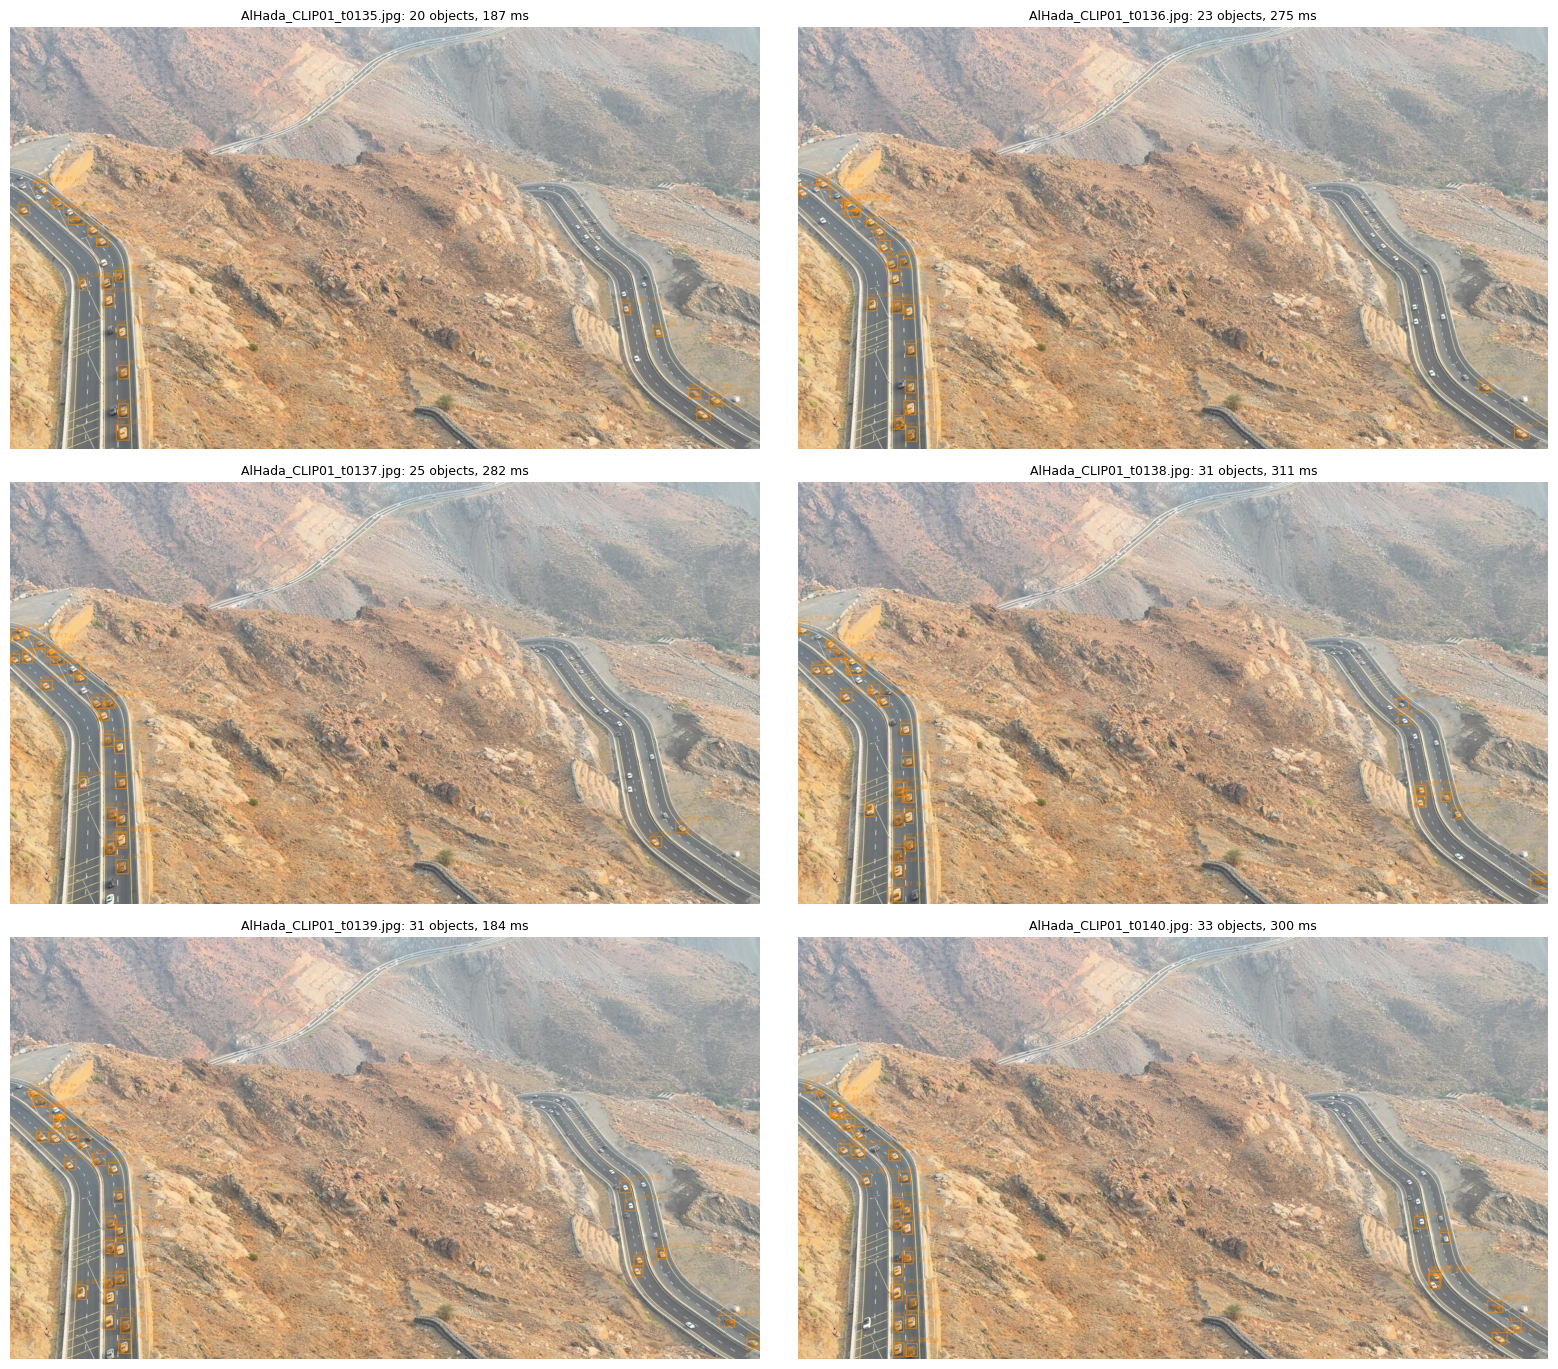

In [10]:
import matplotlib.pyplot as plt
FIGS = []
pick = [r['frame'] for r in ROWS if r['n_objects'] > 0][:N_FIGURES] if FR is not None else []
if pick:
    rows = math.ceil(len(pick) / 2)
    fig, axes = plt.subplots(rows, 2, figsize=(16, 4.6 * rows), squeeze=False)
    for ax in axes.flat: ax.axis('off')
    for ax, k in zip(axes.flat, pick):
        img = load_rgb(FR[k])[0]; res = pipe.analyze(img, altitude_m=ALTITUDE_M, hfov_deg=HFOV_DEG)
        vis = pl.draw(img, res); name = f'figures/{k:03d}_{FR[k].stem}.jpg'
        cv2.imwrite(str(OUT / name), vis[..., ::-1], [cv2.IMWRITE_JPEG_QUALITY, 90]); FIGS.append(name)
        ax.imshow(vis); ax.set_title(f"{FR[k].name}: {len(res['objects'])} objects, {res['timing_ms']['total']:.0f} ms", fontsize=9)
    plt.tight_layout(); plt.show()
else:
    print('no figures (synthetic frames or no detections)')

## 7. Manifest

In [11]:
TIM.drop(columns='boxes_bin').to_csv(OUT / 'frame_timings.csv', index=False)
(OBJS if len(OBJS) else pd.DataFrame(columns=['frame'])).to_csv(OUT / 'objects.csv', index=False)
MANIFEST = {
    'created': time.strftime('%Y-%m-%d %H:%M'), 'output': rel(OUT),
    'pipeline': 'detector -> classifier -> segmentation; one call per image: pipeline.Pipeline.analyze(frame_rgb, altitude_m, hfov_deg)',
    'stages': {'detector': {'checkpoint': rel(DET_W), 'conf': DET_CONF, 'nms_iou': DET_IOU, 'imgsz': DET_IMGSZ, 'classes': DET_CLASS_NAMES},
               'classifier': {'export': rel(CLS), 'classes': clf.CLASSES, 'provider': pipe.cls.get_providers()[0]},
               'segmentation': {'checkpoint': rel(SEG_W), 'backend': SEG_BACKEND, **SEG} if SEG_W else {'status': 'none: mask = None, size from the box'}},
    'size': {'altitude_m': ALTITUDE_M, 'hfov_deg': HFOV_DEG, 'from': 'mask (area, minimum-area rectangle) else box'},
    'frames': FRAME_SOURCE, 'n_frames': len(TIM), 'n_objects': len(OBJS), 'warmup': WARMUP,
    'latency_ms': LAT.to_dict(orient='index'),
    'latency_by_boxes': BY_BOX.reset_index().astype({'boxes_bin': str}).to_dict(orient='records'),
    'budget': {'p95_total_ms_limit': BUDGET_P95_MS, 'p95_total_ms': P95, 'met': P95 <= BUDGET_P95_MS, 'decode_excluded': True},
    'acceptance': ACCEPT, 'figures': FIGS, 'versions': VERSIONS, 'device': DEVICE, 'checks': REPORT,
}
(OUT / 'manifest.json').write_text(json.dumps(MANIFEST, indent=1, default=str))
print('written:', sorted(p.name for p in OUT.iterdir()))

written: ['figures', 'frame_timings.csv', 'manifest.json', 'objects.csv', 'pipeline.py']


## 8. Summary

In [12]:
print(f'frames: {FRAME_SOURCE}')
print(LAT.loc[['detect_ms', 'classify_ms', 'segment_ms', 'size_ms', 'total_ms'], ['p50_ms', 'p95_ms', 'p99_ms']].to_string())
print(f"\nbudget p95 <= {BUDGET_P95_MS} ms: {'MET' if P95 <= BUDGET_P95_MS else 'NOT MET'} ({P95:.1f} ms)")
print(f"acceptance (one call -> class, confidence, box, mask, size): {'MET' if ACCEPT['met'] else 'NOT MET'}")
print('output:', rel(OUT))

frames: 30 frames from 04_Segmentation/seg/yolo_dataset/images/val (seed 42)
             p50_ms  p95_ms  p99_ms
detect_ms     30.70   51.55  107.90
classify_ms   45.52  131.75  168.27
segment_ms    55.23   86.94   94.62
size_ms        3.42    5.07    5.85
total_ms     170.59  279.79  310.01

budget p95 <= 200 ms: NOT MET (279.8 ms)
acceptance (one call -> class, confidence, box, mask, size): NOT MET
output: 04_Integration/2026-11-16_Pipeline_v1
